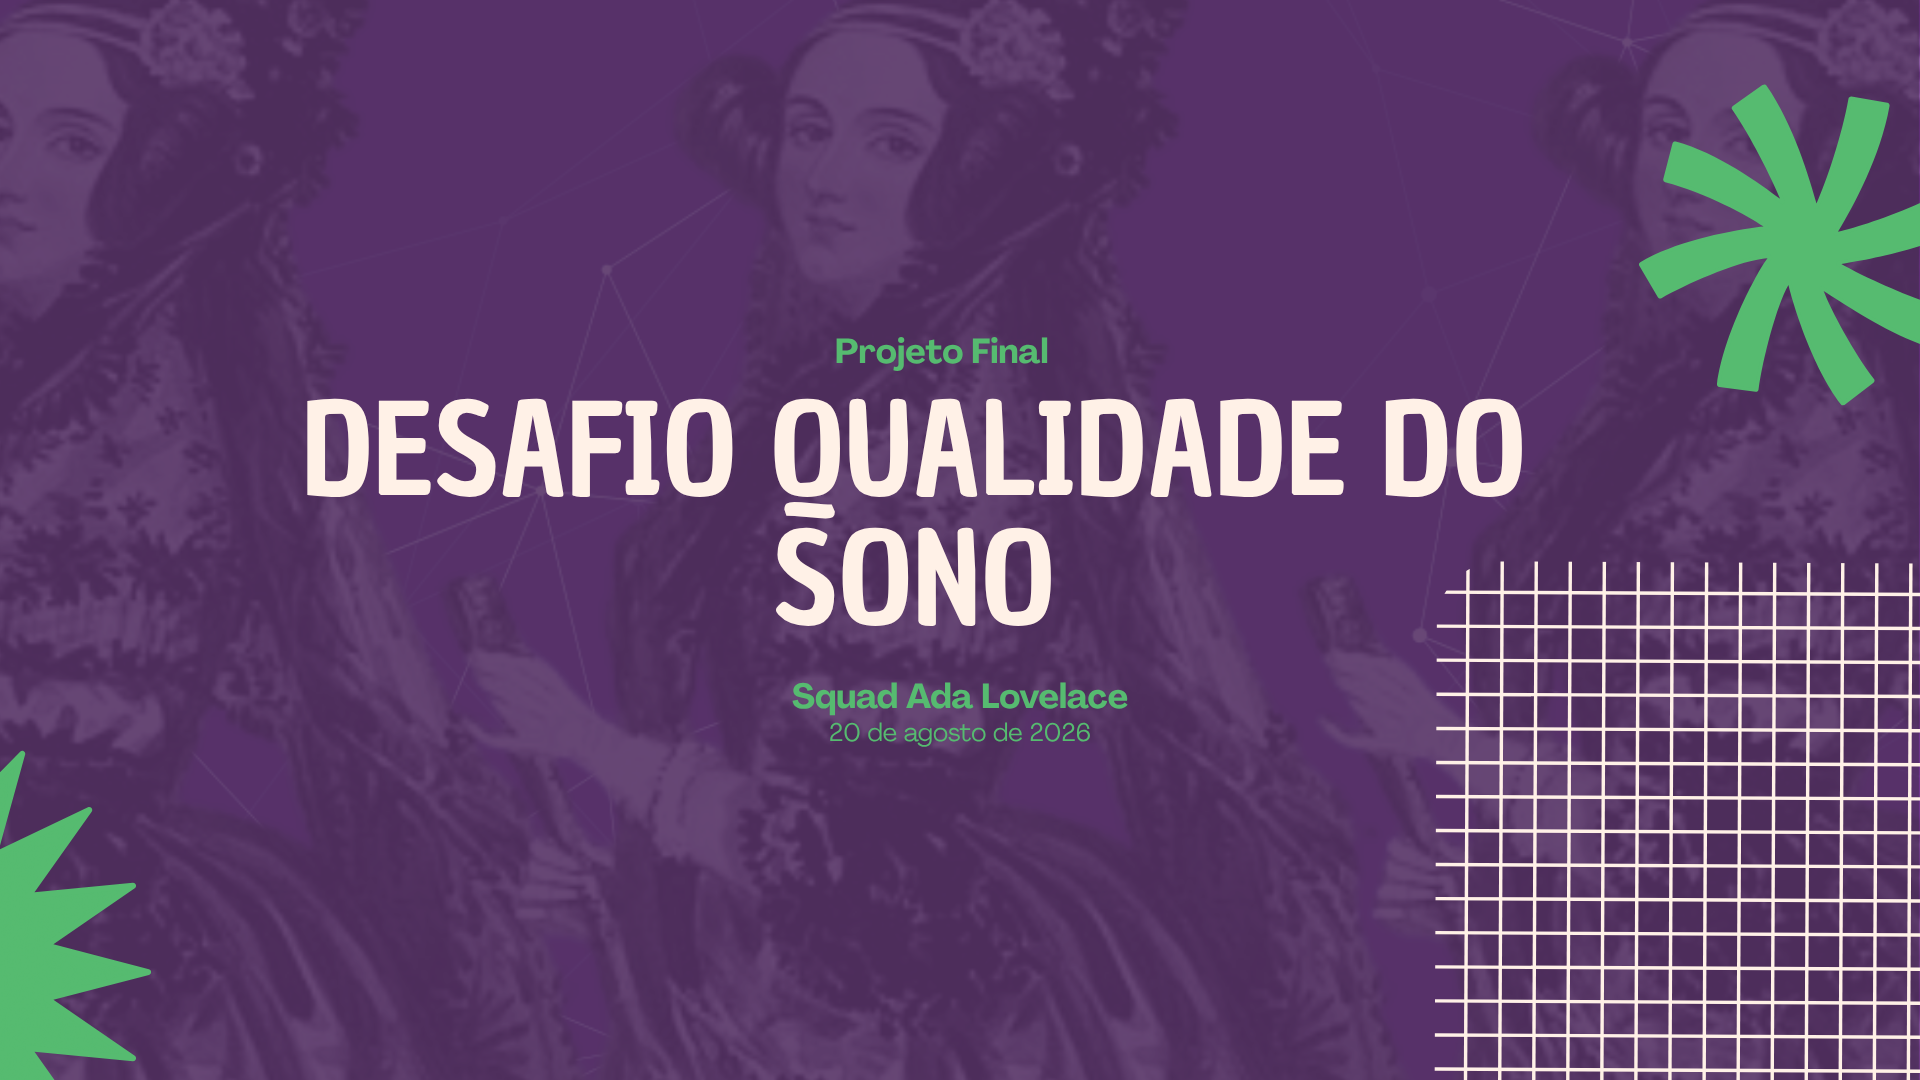

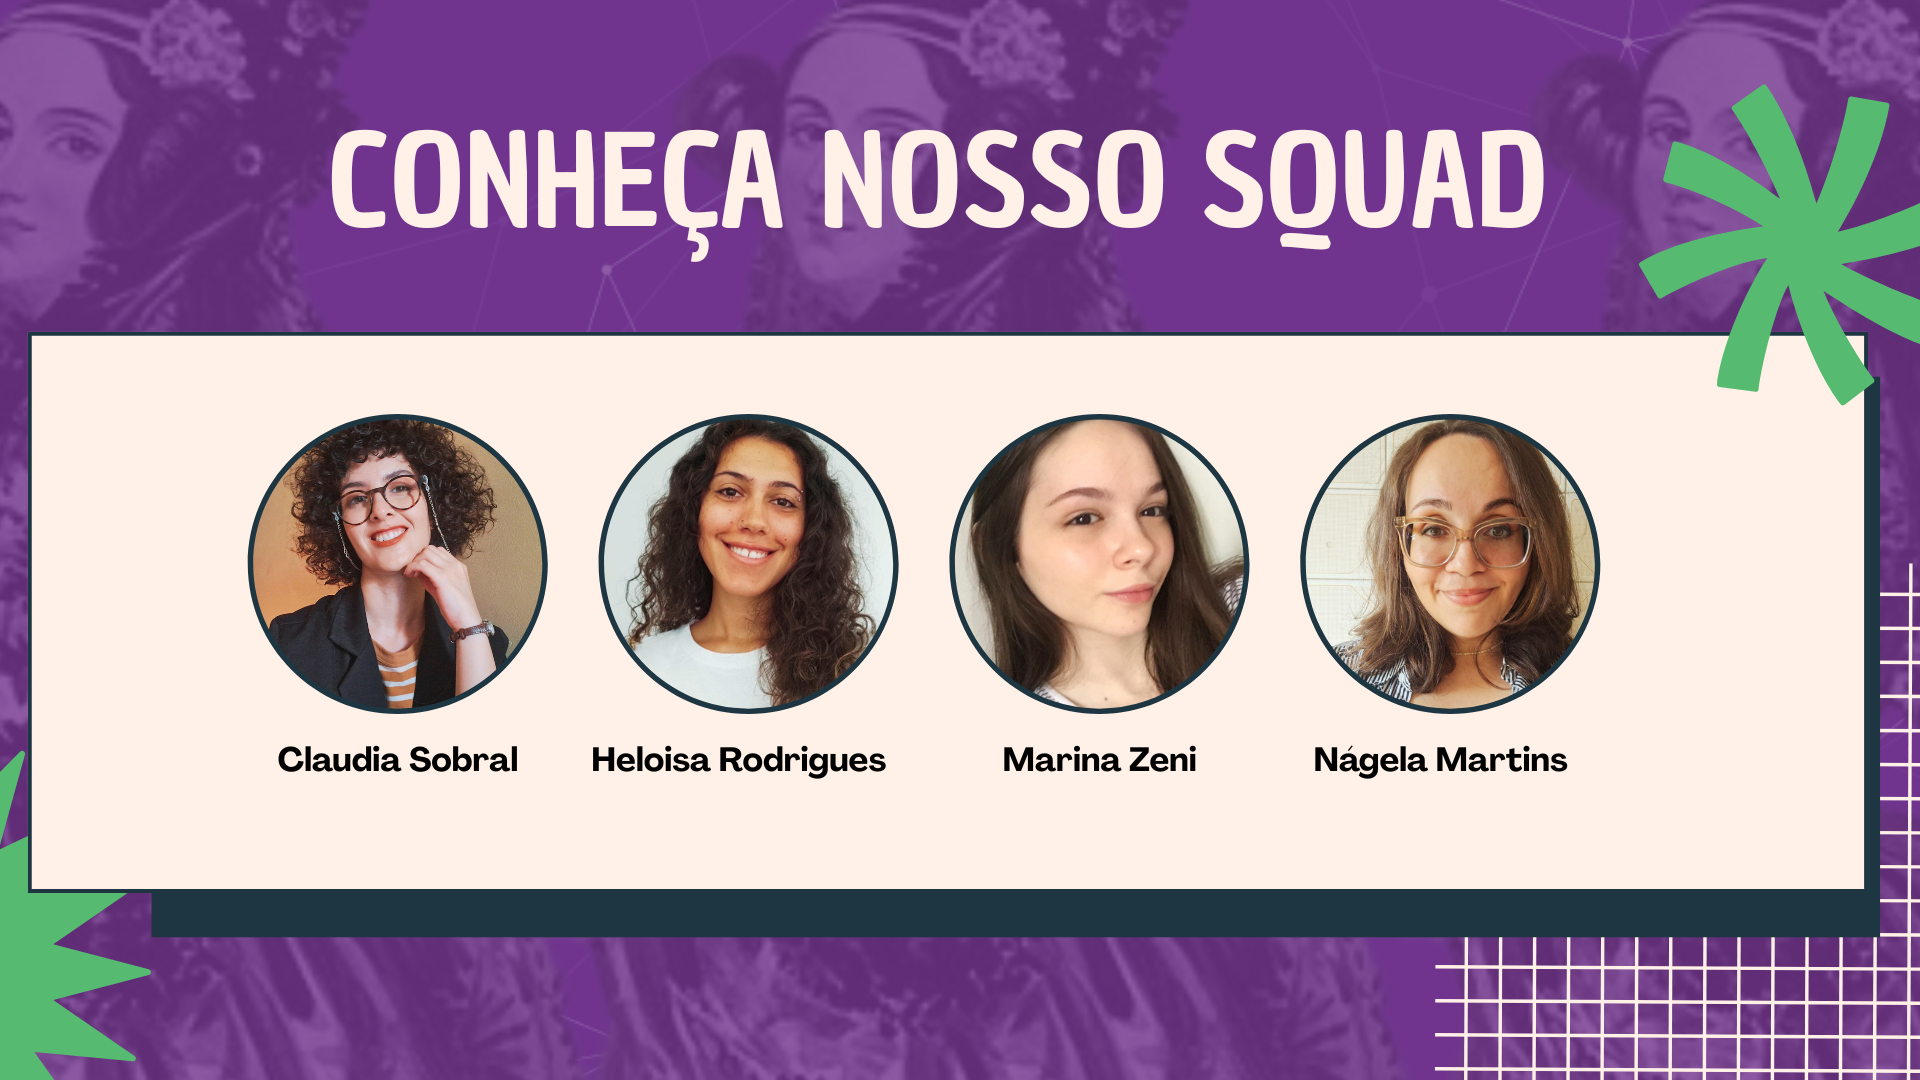

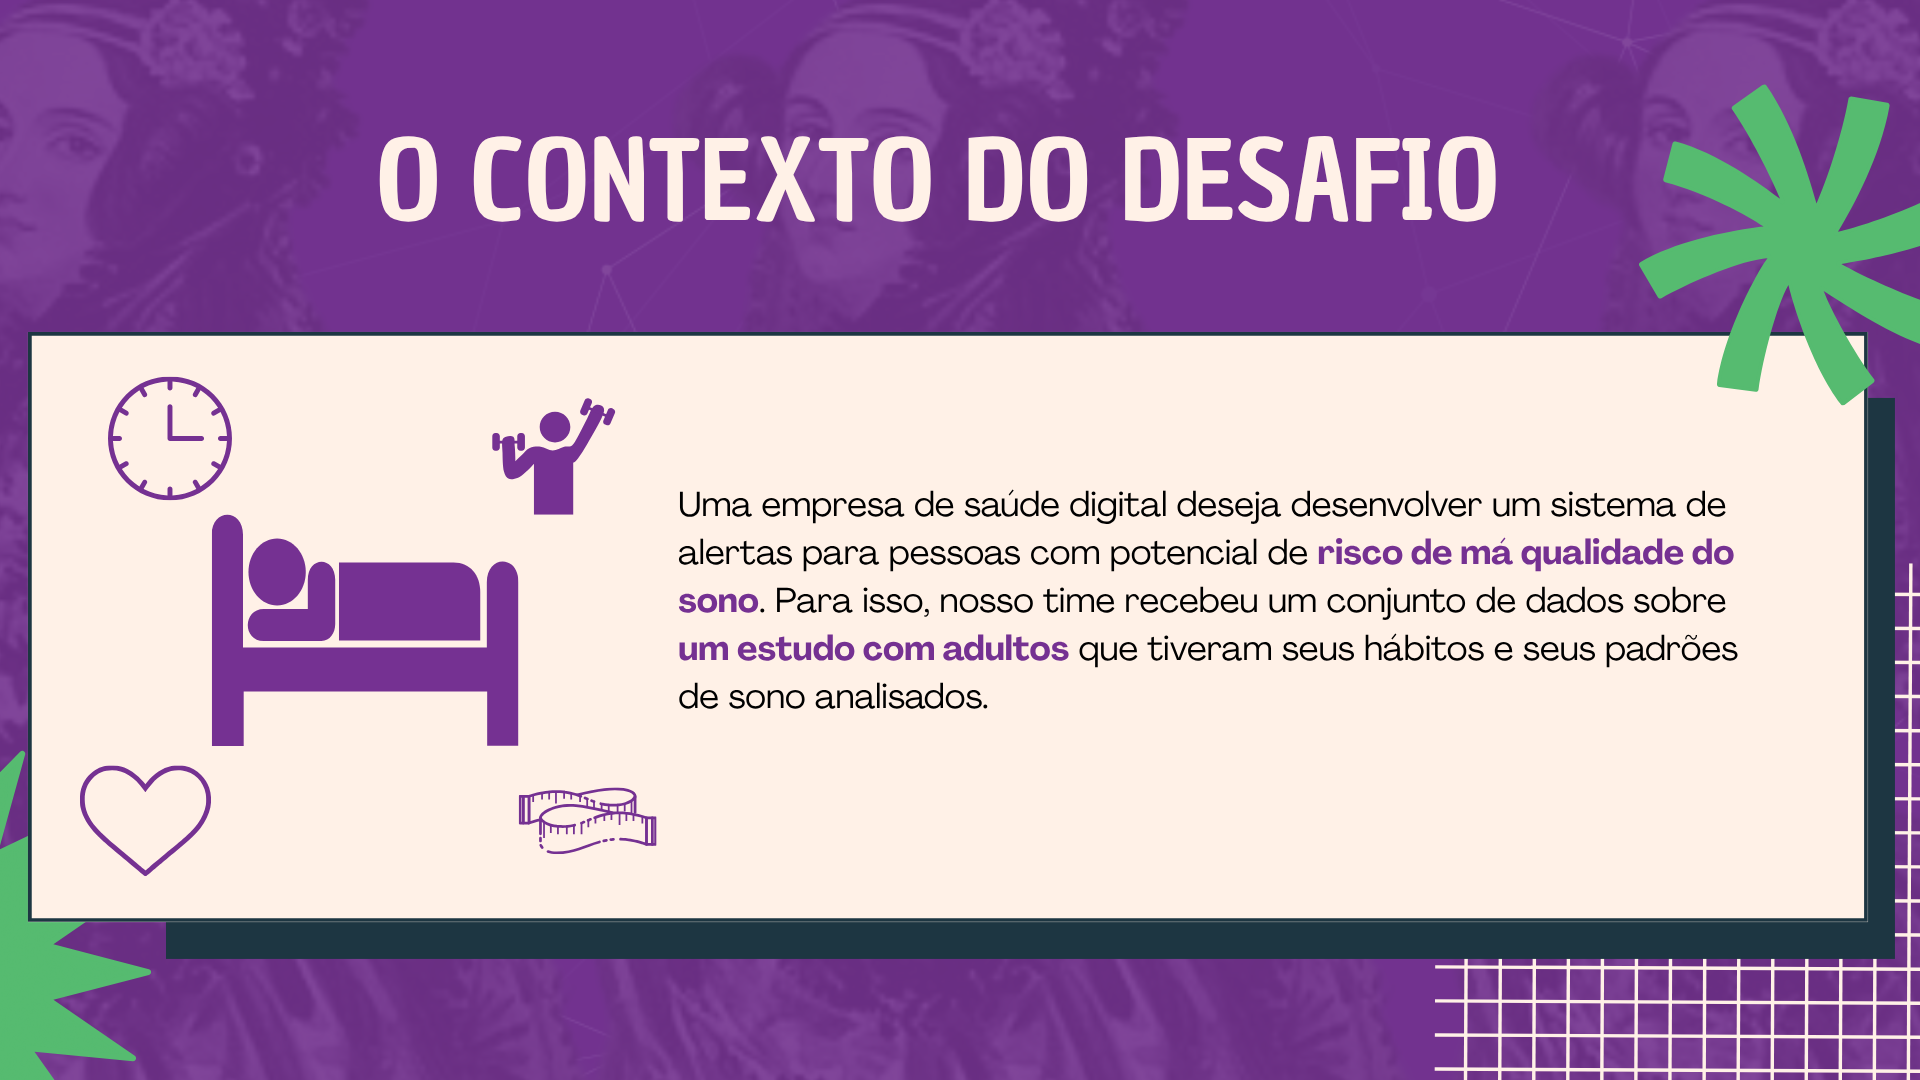

# **Objetivo**

Construir um modelo de machine learning que **classifique a qualidade do sono** (por exemplo, "Boa", "Moderada", "Ruim") com base em variáveis de estilo de vida e saúde. Onde:

**Ruim:** 0-4  
**Moderada:** 5-6  
**Boa:** 7-10

# **Tratamento e preparação do DataFrame**

O tratamento e preparação inicial do DataFrame foi feito em uma etapa separada, e pode ser consultado [aqui.](https://colab.research.google.com/github/squad-ada-lovelace/Desafio_07-Desafio-final/blob/claudia/notebook/notebook_claudia.ipynb)

### O que foi feito:

* **Tradução** dos rótulos das colunas e registros (linhas) para o português;
* Verificação de dados **nulos e duplicados**;
    * Nesse momento, não foram identificados dados duplicados;
    * Somente a coluna `'Sleep Disorder'` `('transtorno do sono')` possuia dados nulos, com **219 registros**. Após verificação, entendemos que esses dados, na verdade, indicavam pessoas que **não possuiam transtornos do sono**. Essa coluna foi, então, tratada e classificada como **'com transtorno' e 'sem transtorno'**;
* Criação de uma **nova coluna** chamada `duração do sono (min)`, com posterior **exclusão** da coluna anterior;
* Tratamento da coluna `'pressao sanguínea'`, **separando os valores entre `'pressao sistolica'` e `'pressao diastolica'`**, com posterior **exclusão** da coluna anterior;
* Criação de uma **nova coluna** chamada `'classificacao pressao'`, com os valores 'pré-hipertensão', 'normal' e 'hipertensão estágio 1';
* Criação de uma **nova coluna** `'categoria qualidade de sono'`, classificada entre 'ruim', 'moderada' e 'boa', de acordo com os intervalos estabelecidos no exercício.

# **Dicionário de Dados**

* **`ID da pessoa`**: Identificador único para cada participante do estudo;
* **`genero`**: Gênero do participante (`masculino` ou `feminino`);
* **`idade`**: Idade do participante em anos;
* **`ocupacao`**: Profissão ou ocupação do participante (ex: engenheiro, enfermeiro, médico, etc.);
* **`qualidade do sono`**: Avaliação subjetiva da qualidade do sono, em uma escala de 1 a 10 (onde valores maiores indicam melhor qualidade);
* **`tempo diario de atividade fisica`**: Quantidade de minutos por dia que o participante dedica a atividades físicas;
* **`nivel de estresse`**: Nível de estresse auto-relatado pelo participante, em uma escala de 1 a 10 (onde valores maiores indicam maior estresse);
* **`classificacao do IMC`**: Categoria do Índice de Massa Corporal do participante (`peso normal`, `sobrepeso`, `obesidade`);
* **`batimentos cardiacos`**: Frequência cardíaca média de repouso do participante em batimentos por minuto (bpm);
* **`passos diarios`**: Número médio de passos que o participante dá por dia;
* **`transtorno do sono`**: Presença ou ausência de transtorno do sono diagnosticado (`sem transtorno`, `com transtorno`);
* **`duracao do sono (min)`**: Duração total do sono do participante calculada em minutos por dia;
* **`pressao sistolica`**: Valor da pressão arterial sistólica (limite superior) em mmHg;
* **`pressao diastolica`**: Valor da pressão arterial diastólica (limite inferior) em mmHg;
* **`categoria qualidade do sono`**: Classificação da qualidade do sono baseada no score numérico (`ruim` [0-4], `moderada` [5-6], `boa` [7-10]);
* **`classificacao pressao`**: Categoria de saúde baseada nos valores de pressão arterial sistólica/diastólica (`normal`, `pré-hipertensão`, `hipertensão estágio 1`).

# **Importações e Análise Exploratória**

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency
import scipy.stats as stats
import statsmodels.api as sm

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer


In [ ]:
df_original = pd.read_csv('https://raw.githubusercontent.com/squad-ada-lovelace/Desafio_07-Desafio-final/refs/heads/claudia/processed/qualidade_do_sono_tratado.csv')
df = df_original.copy()
df

,ID da pessoa,genero,idade,ocupacao,qualidade do sono,tempo diario de atividade fisica,nivel de estresse,classificacao do IMC,batimentos cardiacos,passos diarios,transtorno do sono,duracao do sono (min),pressao sistolica,pressao diastolica,categoria qualidade do sono,classificacao pressao
0,1,masculino,27,engenheiro(a) de software,6,42,6,sobrepeso,77,4200,sem transtorno,366.0,126,83,moderada,pré-hipertensão
1,2,masculino,28,medico(a),6,60,8,peso normal,75,10000,sem transtorno,372.0,125,80,moderada,normal
2,3,masculino,28,medico(a),6,60,8,peso normal,75,10000,sem transtorno,372.0,125,80,moderada,normal
3,4,masculino,28,representante de vendas,4,30,8,obesidade,85,3000,com transtorno,354.0,140,90,ruim,hipertensão estágio 1
4,5,masculino,28,representante de vendas,4,30,8,obesidade,85,3000,com transtorno,354.0,140,90,ruim,hipertensão estágio 1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
369,370,feminino,59,enfermeiro(a),9,75,3,sobrepeso,68,7000,com transtorno,486.0,140,95,boa,hipertensão estágio 1
370,371,feminino,59,enfermeiro(a),9,75,3,sobrepeso,68,7000,com transtorno,480.0,140,95,boa,hipertensão estágio 1
371,372,feminino,59,enfermeiro(a),9,75,3,sobrepeso,68,7000,com transtorno,486.0,140,95,boa,hipertensão estágio 1
372,373,feminino,59,enfermeiro(a),9,75,3,sobrepeso,68,7000,com transtorno,486.0,140,95,boa,hipertensão estágio 1


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 374 entries, 0 to 373
Data columns (total 16 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   ID da pessoa                      374 non-null    int64  
 1   genero                            374 non-null    object 
 2   idade                             374 non-null    int64  
 3   ocupacao                          374 non-null    object 
 4   qualidade do sono                 374 non-null    int64  
 5   tempo diario de atividade fisica  374 non-null    int64  
 6   nivel de estresse                 374 non-null    int64  
 7   classificacao do IMC              374 non-null    object 
 8   batimentos cardiacos              374 non-null    int64  
 9   passos diarios                    374 non-null    int64  
 10  transtorno do sono                374 non-null    object 
 11  duracao do sono (min)             374 non-null    float64
 12  pressao 

In [ ]:
df.shape

(374, 16)

In [ ]:
df.describe()

,ID da pessoa,idade,qualidade do sono,tempo diario de atividade fisica,nivel de estresse,batimentos cardiacos,passos diarios,duracao do sono (min),pressao sistolica,pressao diastolica
count,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000,374.000000
mean,187.500000,42.184492,7.312834,59.171123,5.385027,70.165775,6816.844920,427.925134,128.553476,84.649733
std,108.108742,8.673133,1.196956,20.830804,1.774526,4.135676,1617.915679,47.739404,7.748118,6.161611
min,1.000000,27.000000,4.000000,30.000000,3.000000,65.000000,3000.000000,348.000000,115.000000,75.000000
25%,94.250000,35.250000,6.000000,45.000000,4.000000,68.000000,5600.000000,384.000000,125.000000,80.000000
50%,187.500000,43.000000,7.000000,60.000000,5.000000,70.000000,7000.000000,432.000000,130.000000,85.000000
75%,280.750000,50.000000,8.000000,75.000000,7.000000,72.000000,8000.000000,468.000000,135.000000,90.000000
max,374.000000,59.000000,9.000000,90.000000,8.000000,86.000000,10000.000000,510.000000,142.000000,95.000000


#### Análises variáveis numéricas:

* **Idade**: A amplitude da idade dos participantes varia de 27 a 59 anos, com média de aproximadamente 42 anos. A distribuição é bem equilibrada, com metade dos indivíduos tendo até 43 anos.
* **Qualidade do Sono**: Avaliada em uma escala de 4 a 9, a média geral é de 7.3, sugerindo que a maior parte da amostra percebe sua qualidade de sono como boa (mais de 75% dos indivíduos deram nota 7 ou superior).
* **Duração do Sono**: A média de sono é de aproximadamente 428 minutos (cerca de 7,1 horas) por dia, variando de um mínimo de 348 minutos (5,8 horas) a um máximo de 510 minutos (8,5 horas).
* **Atividade Física e Passos Diários**: Os participantes praticam em média 59 minutos de atividade física diária. O volume de passos diários varia significativamente (de 3.000 a 10.000 passos), com média aproximada de 6.816 passos.
* **Nível de Estresse**: Em uma escala de 3 a 8, a média de estresse é de 5.38. O terceiro quartil (75%) está em 7, indicando que uma parcela considerável reporta níveis de estresse elevados.
* **Batimentos Cardíacos**: A frequência cardíaca média em repouso é de 70 bpm, variando de 65 a 86 bpm, mantendo-se dentro de limites saudáveis para a maioria.
  * **Obs:** Para a maioria dos adultos saudáveis, a frequência cardíaca de repouso (FCR) considerada normal varia entre 60 e 100 batimentos por minuto (bpm).  
[Fonte.](https://www.saolucascopacabana.com.br/blog/batimento-cardiaco-qual-o-normal/)    
  
* **Pressão Arterial**: A pressão sistólica média é de 128.5 mmHg e a diastólica é de 84.6 mmHg. O valor máximo de 142/95 mmHg indica a presença de indivíduos na amostra com critérios de hipertensão. E o valor mínimo de 115/75 indica hipotensão.  
  * Classificação da pressão arterial ([Fonte](https://educare.fiocruz.br/resource/show?id=dWeplNRx)):  
| Classificação | Limites de definição |
|---|---|
| Pressão arterial ótima | PAS: < 120 mmHg e PAD: < 80 mmHg |
| Pressão arterial normal | PAS: 120 - 129 mmHg e/ou PAD: 80 - 84 mmHg |
| Pré-hipertensão | PAS: 130 - 139 mmHg e/ou PAD: 85 - 89 mmHg |
| Hipertensão Arterial Estágio I | PAS: 140 - 159 mmHg e/ou PAD: 90 - 99 mmHg |
| Hipertensão Arterial Estágio II | PAS: 160 - 179 mmHg e/ou PAD: 100 - 109 mmHg |
| Hipertensão Arterial Estágio III | PAS: ≥ 180 mmHg e/ou PAD: ≥ 110 mmHg |

In [ ]:
df.describe(include='object')

,genero,ocupacao,classificacao do IMC,transtorno do sono,categoria qualidade do sono,classificacao pressao
count,374,374,374,374,374,374
unique,2,11,3,2,3,3
top,masculino,enfermeiro(a),peso normal,sem transtorno,boa,normal
freq,189,73,216,219,257,182


#### Análises variáveis categóricas:

* **Gênero**: A base de dados é muito bem equilibrada entre os sexos, com uma leve predominância do gênero **masculino** (189 dos 374 registros, representando cerca de 50.5% da amostra).
* **Ocupação**: Há **11 ocupações únicas** na base de dados, sendo a de **enfermeiro(a)** a mais frequente, com 73 ocorrências na amostra.
* **Classificação do IMC**: Existem **3 classificações únicas** de IMC. A categoria mais comum é **peso normal**, com 216 indivíduos da amostra.
* **Transtorno do Sono**: A variável apresenta **2 categorias** (com ou sem transtorno). A grande maioria dos indivíduos (**219 participantes**) **não possui nenhum transtorno de sono** diagnosticado.
* **Categoria de Qualidade do Sono**: Dividida em **3 categorias únicas**, sendo a classificação **boa** a mais frequente, abrangendo 257 participantes.
* **Classificacao pressao** demonstra que a maioria (182) das pessoas possuem pressão normal.

In [ ]:
# Verificando nulos, linhas duplicadas e contagem de valores categóricos no dataset tratado

def analisar_dataset(dataframe):
    # 1. Verificação de Duplicados
    duplicados = dataframe.duplicated().sum()
    print("="*50)
    print(f"Análise de Duplicados: {duplicados} linha(s) duplicada(s) encontrada(s).")
    print("="*50 + "\n")

    # 2. Resumo de Nulos e Valores Únicos
    print("Resumo de Nulos e Valores Únicos por Coluna:")
    resumo = pd.DataFrame({
        'Nulos (Qtd)': dataframe.isnull().sum(),
        'Nulos (%)': (dataframe.isnull().sum() / len(dataframe) * 100).round(2),
        'Valores Únicos (Qtd)': dataframe.nunique(),
        'Tipo de Dado': dataframe.dtypes
    })
    display(resumo)
    print("\n" + "="*50 + "\n")

    # 3. Contagem de Valores (Value Counts) para colunas categóricas
    print("Distribuição de Valores (Value Counts) para colunas categóricas:")
    colunas_categoricas = dataframe.select_dtypes(include=['object', 'category']).columns

    for col in colunas_categoricas:
        print(f"\n--- Coluna: {col} ---")
        print(dataframe[col].value_counts())
        print("-"*30)

# Executar a função no seu dataset
analisar_dataset(df)

Análise de Duplicados: 0 linha(s) duplicada(s) encontrada(s).

Resumo de Nulos e Valores Únicos por Coluna:


,Nulos (Qtd),Nulos (%),Valores Únicos (Qtd),Tipo de Dado
ID da pessoa,0,0.0,374,int64
genero,0,0.0,2,object
idade,0,0.0,31,int64
ocupacao,0,0.0,11,object
qualidade do sono,0,0.0,6,int64
tempo diario de atividade fisica,0,0.0,16,int64
nivel de estresse,0,0.0,6,int64
classificacao do IMC,0,0.0,3,object
batimentos cardiacos,0,0.0,19,int64
passos diarios,0,0.0,20,int64




Distribuição de Valores (Value Counts) para colunas categóricas:

--- Coluna: genero ---
genero
masculino    189
feminino     185
Name: count, dtype: int64
------------------------------

--- Coluna: ocupacao ---
ocupacao
enfermeiro(a)                73
medico(a)                    71
engenheiro(a)                63
advogado(a)                  47
professor(a)                 40
contador(a)                  37
vendedor(a)                  32
cientista                     4
engenheiro(a) de software     4
representante de vendas       2
gerente                       1
Name: count, dtype: int64
------------------------------

--- Coluna: classificacao do IMC ---
classificacao do IMC
peso normal    216
sobrepeso      148
obesidade       10
Name: count, dtype: int64
------------------------------

--- Coluna: transtorno do sono ---
transtorno do sono
sem transtorno    219
com transtorno    155
Name: count, dtype: int64
------------------------------

--- Coluna: categoria qualidade do so

In [ ]:
# Verificando existência de Outliers

def detectar_outliers_iqr(dataframe):
    # Identificar apenas as colunas numéricas (ignorando o ID da pessoa)
    colunas_numericas = dataframe.select_dtypes(include=['int64', 'float64']).columns
    if 'ID da pessoa' in colunas_numericas:
        colunas_numericas = colunas_numericas.drop('ID da pessoa')

    print("=" * 80)
    print("Análise de Outliers utilizando o Método IQR (Limite de 1.5)")
    print("=" * 80 + "\n")

    outliers_encontrados = False

    for col in colunas_numericas:
        # Cálculo do IQR
        Q1 = dataframe[col].quantile(0.25)
        Q3 = dataframe[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Filtrando os outliers
        outliers = dataframe[(dataframe[col] < lower_bound) | (dataframe[col] > upper_bound)]

        if len(outliers) > 0:
            outliers_encontrados = True
            print(f"Coluna: '{col}' | Encontrados {len(outliers)} outlier(s)")
            print(f"Limites: Inferior = {lower_bound:.2f} | Superior = {upper_bound:.2f}")
            display(outliers[[col]])
            print("-" * 80 + "\n")
        else:
            print(f"Coluna: '{col}' | Nenhum outlier encontrado.")
            print("-" * 80 + "\n")

    if not outliers_encontrados:
        print("Nenhum outlier foi detectado em nenhuma das colunas numéricas.")

# Executar a detecção no seu dataset
detectar_outliers_iqr(df)

Análise de Outliers utilizando o Método IQR (Limite de 1.5)

Coluna: 'idade' | Nenhum outlier encontrado.
--------------------------------------------------------------------------------

Coluna: 'qualidade do sono' | Nenhum outlier encontrado.
--------------------------------------------------------------------------------

Coluna: 'tempo diario de atividade fisica' | Nenhum outlier encontrado.
--------------------------------------------------------------------------------

Coluna: 'nivel de estresse' | Nenhum outlier encontrado.
--------------------------------------------------------------------------------

Coluna: 'batimentos cardiacos' | Encontrados 15 outlier(s)
Limites: Inferior = 62.00 | Superior = 78.00


,batimentos cardiacos
3,85
4,85
5,85
6,82
16,80
18,80
80,81
81,81
93,84
145,84


--------------------------------------------------------------------------------

Coluna: 'passos diarios' | Nenhum outlier encontrado.
--------------------------------------------------------------------------------

Coluna: 'duracao do sono (min)' | Nenhum outlier encontrado.
--------------------------------------------------------------------------------

Coluna: 'pressao sistolica' | Nenhum outlier encontrado.
--------------------------------------------------------------------------------

Coluna: 'pressao diastolica' | Nenhum outlier encontrado.
--------------------------------------------------------------------------------



Apesar de existirem **outliers nos batimentos cardíacos**, optamos por **mante-los**, pois, na medicina uma frequência cardíaca de repouso de até 86 bpm (o valor máximo registrado no dataset) é considerada perfeitamente normal e comum para adultos saudáveis (a faixa normal vai de 60 a 100 bpm). Portanto, esses dados representam variações biológicas reais de pacientes reais, e não erros de digitação, falhas de sensores ou ruídos.

## Visualizações

/tmp/ipykernel_4939/940574731.py:25: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.countplot(ax=axes[1, 0], data=df, x='categoria qualidade do sono', hue='genero', order=ordem_categorias, palette=paleta_agrupadas)
/tmp/ipykernel_4939/940574731.py:33: UserWarning: The palette list has more values (3) than needed (2), which may not be intended.
  sns.countplot(ax=axes[2, 0], data=df, x='categoria qualidade do sono', hue='transtorno do sono', order=ordem_categorias, palette=paleta_agrupadas)


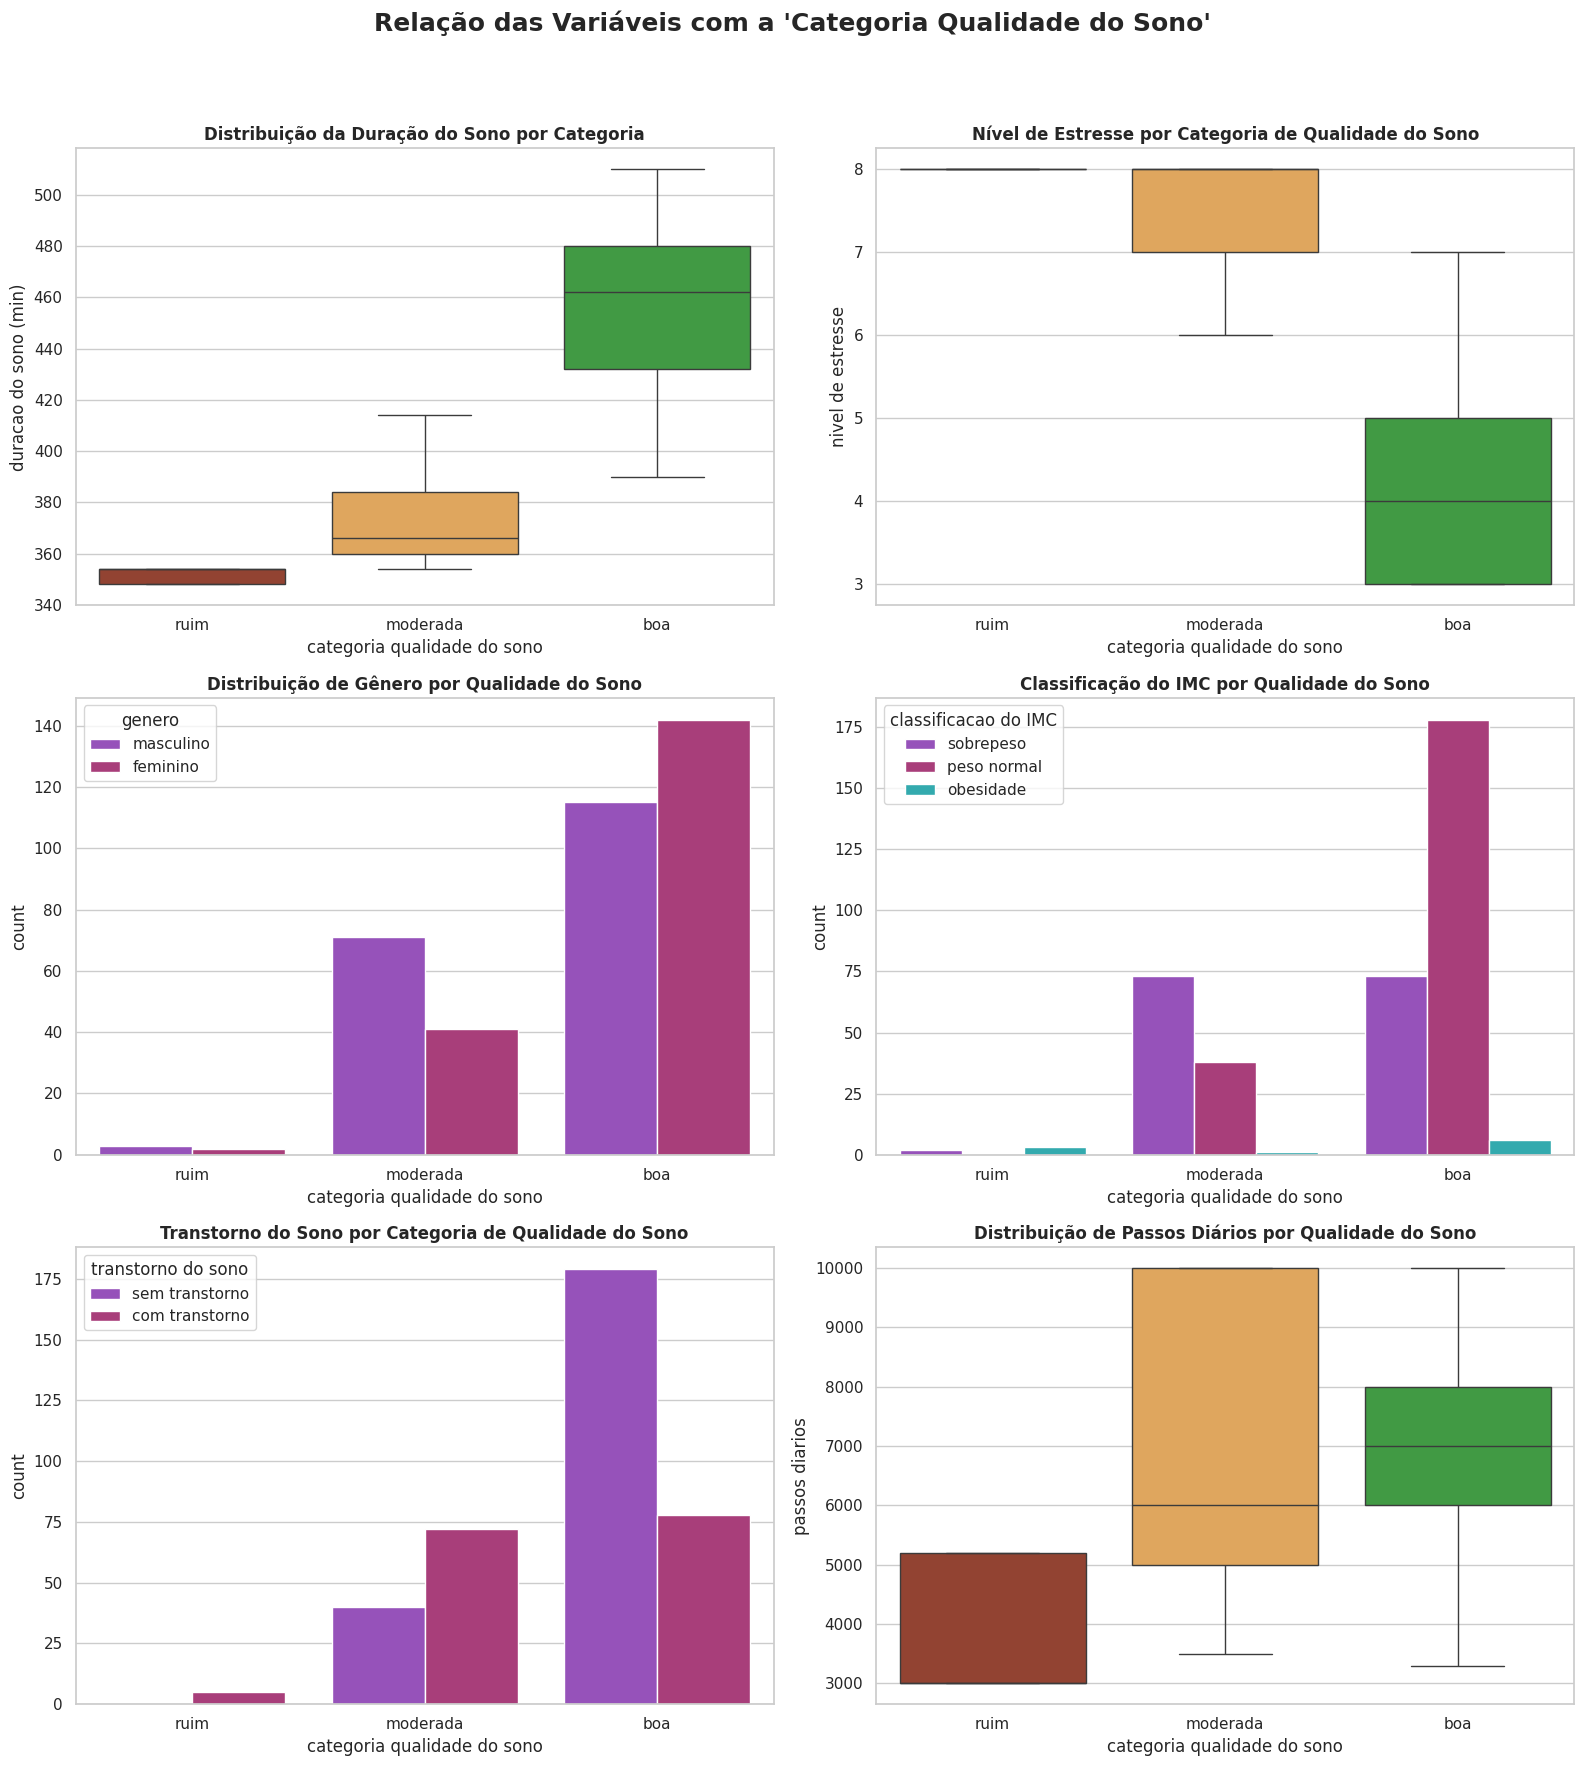

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
palette_cores = ['#F4A949', '#A23922', '#32A936']
paleta_agrupadas = ['#9B41CB', '#BA2C7C', '#1EBDC3']
sns.set_palette(palette_cores)

plt.rcParams['figure.figsize'] = (10, 8)
ordem_categorias = ['ruim', 'moderada', 'boa']

# Criando uma figura com múltiplos subplots para analisar as relações com a Target
fig, axes = plt.subplots(3, 2, figsize=(16, 18))
fig.suptitle("Relação das Variáveis com a 'Categoria Qualidade do Sono'", fontsize=18, fontweight='bold', y=0.98)

# 1. Duração do Sono
sns.boxplot(ax=axes[0, 0], data=df, x='categoria qualidade do sono', y='duracao do sono (min)', hue='categoria qualidade do sono', order=ordem_categorias, palette=palette_cores, legend=False)
axes[0, 0].set_title("Distribuição da Duração do Sono por Categoria", fontsize=12, fontweight='bold')

# 2. Nível de Estresse
sns.boxplot(ax=axes[0, 1], data=df, x='categoria qualidade do sono', y='nivel de estresse', hue='categoria qualidade do sono', order=ordem_categorias, palette=palette_cores, legend=False)
axes[0, 1].set_title("Nível de Estresse por Categoria de Qualidade do Sono", fontsize=12, fontweight='bold')

# 3. Gênero
sns.countplot(ax=axes[1, 0], data=df, x='categoria qualidade do sono', hue='genero', order=ordem_categorias, palette=paleta_agrupadas)
axes[1, 0].set_title("Distribuição de Gênero por Qualidade do Sono", fontsize=12, fontweight='bold')

# 4. Classificação do IMC
sns.countplot(ax=axes[1, 1], data=df, x='categoria qualidade do sono', hue='classificacao do IMC', order=ordem_categorias, palette=paleta_agrupadas)
axes[1, 1].set_title("Classificação do IMC por Qualidade do Sono", fontsize=12, fontweight='bold')

# 5. Transtorno do Sono
sns.countplot(ax=axes[2, 0], data=df, x='categoria qualidade do sono', hue='transtorno do sono', order=ordem_categorias, palette=paleta_agrupadas)
axes[2, 0].set_title("Transtorno do Sono por Categoria de Qualidade do Sono", fontsize=12, fontweight='bold')

# 6. Passos Diários
sns.boxplot(ax=axes[2, 1], data=df, x='categoria qualidade do sono', y='passos diarios', hue='categoria qualidade do sono', order=ordem_categorias, palette=palette_cores, legend=False)
axes[2, 1].set_title("Distribuição de Passos Diários por Qualidade do Sono", fontsize=12, fontweight='bold')

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

#### Análises:  

* **Duração do Sono:** Há uma relação direta muito clara: quanto maior a duração do sono (em minutos), melhor é a classificação da qualidade. Quem tem qualidade de sono ruim dorme consideravelmente menos minutos por dia comparado a quem tem qualidade de sono boa.  

* **Nível de Estresse:** O nível de estresse se mostra inversamente proporcional à qualidade do sono. Indivíduos com qualidade de sono ruim apresentam os maiores níveis de estresse do conjunto de dados, enquanto aqueles com qualidade de sono boa mantêm os níveis de estresse visivelmente mais baixos.

* **Gênero:** Disparidade por Categoria. Embora a base de dados seja equilibrada, há uma clara distinção: o público feminino predomina amplamente na qualidade de sono classificada como boa. Em contrapartida, os homens representam a grande maioria na classificação de qualidade de sono moderada.

* **Classificação do IMC:** Indivíduos com classificação de IMC normal possuem uma propensão muito maior a ter uma qualidade de sono boa. Por outro lado, quem está nas categorias de sobrepeso ou obesidade concentra-se fortemente nas faixas de qualidade de sono moderada e ruim.

* **Transtorno do Sono:** A presença de algum transtorno de sono (como insônia ou apneia) está ligada a uma qualidade de sono pior. Os participantes sem transtorno dominam a categoria de qualidade de sono boa, ao passo que as qualidades moderada ou ruim possui maioria classificada com algum transtorno do sono.

* **Passos Diários:** Pessoas com qualidade de sono boa ou moderada mantêm uma mediana de passos diários mais elevada e consistente (comportamento ativo). Já a qualidade de sono ruim apresenta uma dispersão maior, mas com uma mediana de passos ligeiramente inferior, indicando que níveis muito baixos de atividade física diária podem estar associados a noites piores de sono.

## Análise de correlação

### Variáveis categóricas e qualidade de sono

Para investigar a existência de **associação entre as variáveis categóricas** e os níveis de qualidade do sono, foi aplicado o teste do qui-quadrado de independência associado ao cramers_v.

* **Qui-quadrado:** diz **se existe uma conexão** estatisticamente relevante (uma associação) entre as duas variáveis. Se o p-valor for menor que 0.05 existe correlação;
* **Cramers V:** fórmula matemática que utiliza o Qui-quadrado para dizer o **quão forte é essa conexão** que o Qui-quadrado encontrou, variando sempre de 0 (nenhuma associação) a 1 (associação perfeita).

In [ ]:
def cramers_v(tabela):
  chi2, p, dof, esperado = chi2_contingency(tabela)

  n = tabela.sum().sum()
  r, k = tabela.shape

  phi2 = chi2 / n

  phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))

  r_corr = r - ((r - 1) ** 2) / (n - 1)
  k_corr = k - ((k - 1) ** 2) / (n - 1)

  v = np.sqrt(phi2_corr / min(k_corr - 1, r_corr - 1))

  return v

def analisar_categoricas(df, colunas, target):
  resultados = []

  for coluna in colunas:

    tabela = pd.crosstab(df[coluna],df[target])

    # Qui quadrado: verifica se há associação estatisticamente significativa entre duas variáveis categóricas
    chi2, p, dof, esperado = chi2_contingency(tabela)

    v = cramers_v(tabela)

    resultados.append({
        "variavel": coluna,
        "qui_quadrado": chi2,
        "p_valor": p,
        "cramers_v": v
    })

  resultado = pd.DataFrame(resultados)

  return resultado.sort_values( "cramers_v", ascending=False)

colunas_categoricas = ["genero", "ocupacao", "transtorno do sono"]
resultado_categoricos = analisar_categoricas(df, colunas_categoricas, "categoria qualidade do sono")
resultado_categoricos["p<0,05"] = (resultado_categoricos["p_valor" ] < 0.05)

resultado_categoricos.round(4)

,variavel,qui_quadrado,p_valor,cramers_v,"p<0,05"
1,ocupacao,407.3753,0.000,0.7215,True
2,transtorno do sono,44.1772,0.000,0.3362,True
0,genero,11.0308,0.004,0.1556,True


#### Análises de correlação variáveis categóricas

* `Ocupação` (Cramér's V: 0.7215 / p-valor: 0.0000):
    * Força da Associação: **Muito Forte**.
    * Análise: Esta é a variável categórica mais fortemente associada à qualidade do sono no conjunto de dados. Isso significa que a profissão de uma pessoa é um indicativo fortíssimo de como será a qualidade do sono dela.

* `Transtorno do Sono` (Cramér's V: 0.3362 / p-valor: 0.0000):
    * Força da Associação: **Moderada**.
    * Análise: Há uma associação estatisticamente relevante e clara. Indivíduos que apresentam algum transtorno diagnosticado (como insônia ou apneia) possuem uma qualidade de sono notavelmente inferior em comparação àqueles sem nenhum transtorno.
* `Gênero` (Cramér's V: 0.1556 / p-valor: 0.0040):
    * Força da Associação: **Fraca**.
    * Análise: Embora o teste de Qui-quadrado aponte que existe uma diferença real entre os gêneros (p-valor de 0.004 é menor que 0.05), a força dessa associação medida pelo V de Cramér é baixa. Ou seja, há sim uma sutil diferença no comportamento do sono entre homens e mulheres (como visto nos gráficos onde as mulheres têm uma proporção ligeiramente maior de sono 'boa'), mas o gênero isoladamente não é um fator tão determinante quanto a ocupação ou a presença de transtornos.

#### Visualização

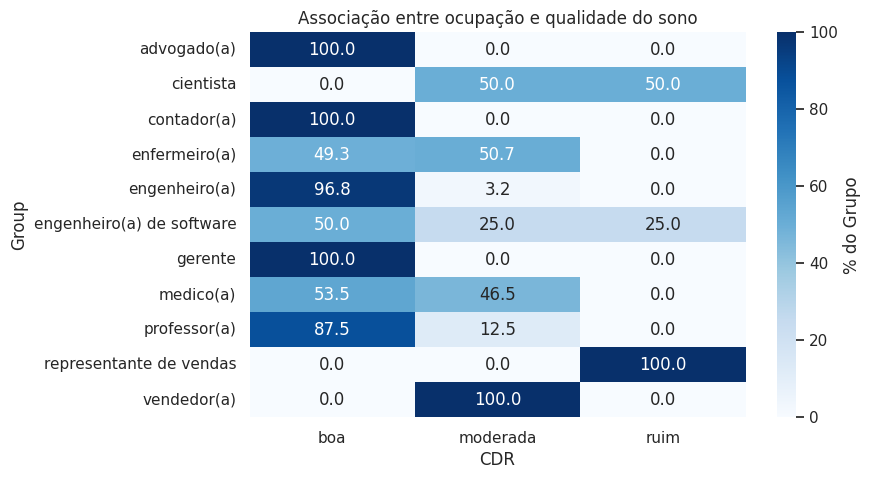

In [ ]:
tabela_contingencia_ocupacao = pd.crosstab(df['ocupacao'], df['categoria qualidade do sono'], normalize='index') * 100

plt.figure(figsize=(8, 5))
sns.heatmap(tabela_contingencia_ocupacao, annot=True, fmt=".1f", cmap="Blues", cbar_kws={'label': '% do Grupo'})

plt.title("Associação entre ocupação e qualidade do sono")
plt.xlabel("CDR")
plt.ylabel("Group")
plt.show()

#### Conclusões:

A tabela normalizada por linha (% do Grupo) mostra que a profissão está fortemente atrelada à qualidade de sono. Ela identifica quais categorias de trabalhadores concentram as melhores e as piores faixas de sono.

* Qualidade de Sono Excelente:
    * Advogados(as), contadores(as) e gerente(as) apresentam 100.0% de seus registros na categoria de qualidade de sono boa. Esses grupos concentram os maiores percentuais de sono bom na amostra.
    * Engenheiros(as) apresentam 96.8% representantes com qualidade de sono boa, com apenas 3.2% referentes ao grupo moderado.

* Qualidade de Sono Equilibrada/Crítica:
    * Enfermeiros(as): É o maior grupo da amostra. Destes, 49.3% possuem qualidade de sono boa, mas 50.7% encontram-se na categoria moderada.
    * Engenheiros(as) de software: concentração maior dos representantes com qualidade do sono boa (50%), porém o restante é igualmente distribuído em moderado (25%) e ruim (25%).
    * Médicos(as): Apresentam uma distribuição dividida. 53.5% têm sono bom, enquanto 46.5% têm qualidade de sono moderada.
    * Professores(as): 87.5% estão na categoria boa e 12.5% na moderada.

* Grupos de Alerta:
    * Vendedores(as): Este grupo apresenta um sinal de atenção, pois 100.0% de seus membros têm qualidade de sono classificada apenas como moderada.
    * Cientistas: É um dos grupos de maior criticidade, dividindo-se entre 50.0% moderada e 50.0% ruim.
    * Representantes de vendas: Trata-se do pior cenário, onde 100.0% dos profissionais registram qualidade de sono ruim.

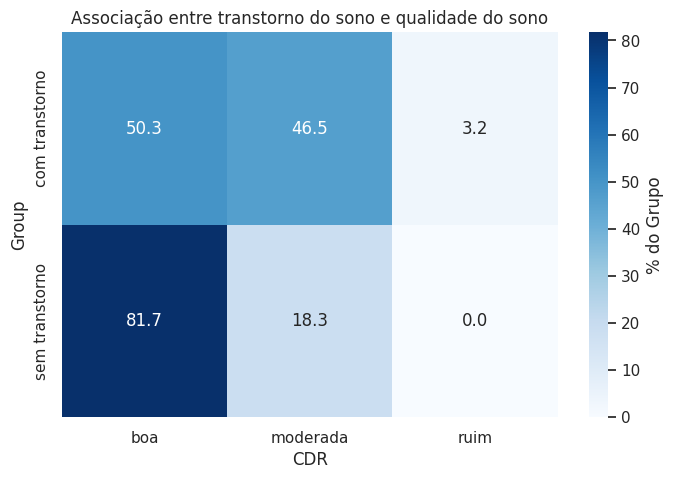

In [ ]:
tabela_contingencia_transtorno_sono = pd.crosstab(df['transtorno do sono'], df['categoria qualidade do sono'], normalize='index') * 100

plt.figure(figsize=(8, 5))
sns.heatmap(tabela_contingencia_transtorno_sono, annot=True, fmt=".1f", cmap="Blues", cbar_kws={'label': '% do Grupo'})

plt.title("Associação entre transtorno do sono e qualidade do sono")
plt.xlabel("CDR")
plt.ylabel("Group")
plt.show()

#### Conclusões:

Esses dados comprovam estatisticamente a associação moderada medida pelo teste de Cramér's V (0.3362): a **ausência de transtornos** é um forte indicativo de **noites bem dormidas** (com mais de **81%** de chances de ter sono bom). Já o **diagnóstico de um transtorno** atua como uma barreira relevante, **reduzindo as chances de um sono de alta qualidade** pela metade e abrindo margem para o surgimento de sono clinicamente classificado como ruim.

* Indivíduos Sem Transtorno do Sono:
    * Apresentam a melhor **consistência** de sono. 81.7% das pessoas que não têm nenhum transtorno diagnosticado desfrutam de uma qualidade de sono boa.
    * Apenas 18.3% delas têm qualidade de sono moderada e 0.0% (nenhuma pessoa) apresenta qualidade de sono ruim.

* Indivíduos Com Transtorno do Sono (ex: Insônia ou Apneia):
    * Há uma **queda drástica no padrão de qualidade**. Apenas 50.3% (quase a metade) consegue manter uma qualidade de sono boa.
    * Um contingente expressivo de 46.5% fica restrito à qualidade de sono moderada.
    * É nesta categoria que se **concentram os casos mais graves**: 3.2% das pessoas com transtorno relatam uma qualidade de sono ruim.



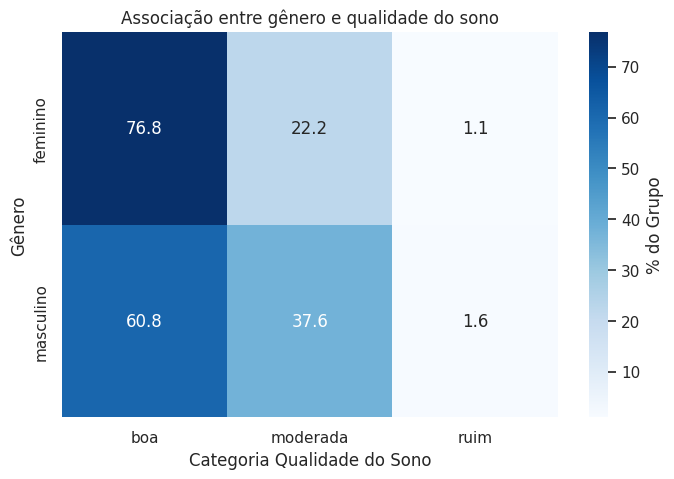

In [ ]:
tabela_contingencia_genero = pd.crosstab(df['genero'], df['categoria qualidade do sono'], normalize='index') * 100

plt.figure(figsize=(8, 5))
sns.heatmap(tabela_contingencia_genero, annot=True, fmt=".1f", cmap="Blues", cbar_kws={'label': '% do Grupo'})

plt.title("Associação entre gênero e qualidade do sono")
plt.xlabel("Categoria Qualidade do Sono")
plt.ylabel("Gênero")
plt.show()

#### Conclusões:

Embora o teste de Qui-quadrado aponte que existe uma diferença estatisticamente relevante entre os gêneros (p-valor: 0.004), a força dessa associação medida pelo V de Cramér é baixa (0.1556), mostrando que o gênero isoladamente não é tão determinante quanto a ocupação ou a presença de transtornos.

* **Gênero Feminino:**
    * Apresenta uma maior proporção de sono de alta qualidade, com **76.8%** das mulheres registrando qualidade de sono **boa**.
    * **22.2%** possuem qualidade de sono **moderada** e apenas **1.1%** apresentam qualidade de sono **ruim**.

* **Gênero Masculino:**
    * Os homens registram um comportamento ligeiramente inferior na faixa de alta qualidade, com **60.8%** na categoria **boa**.
    * Em contrapartida, concentram uma fatia maior na categoria **moderada** (**37.6%**) e **1.6%** na categoria **ruim**.

### Variáveis numéricas e qualidade de sono

É usado o método de Spearman, uma vez que as variáveis não seguem uma distribuição normal, como pode ser visto no QQ-Plot.

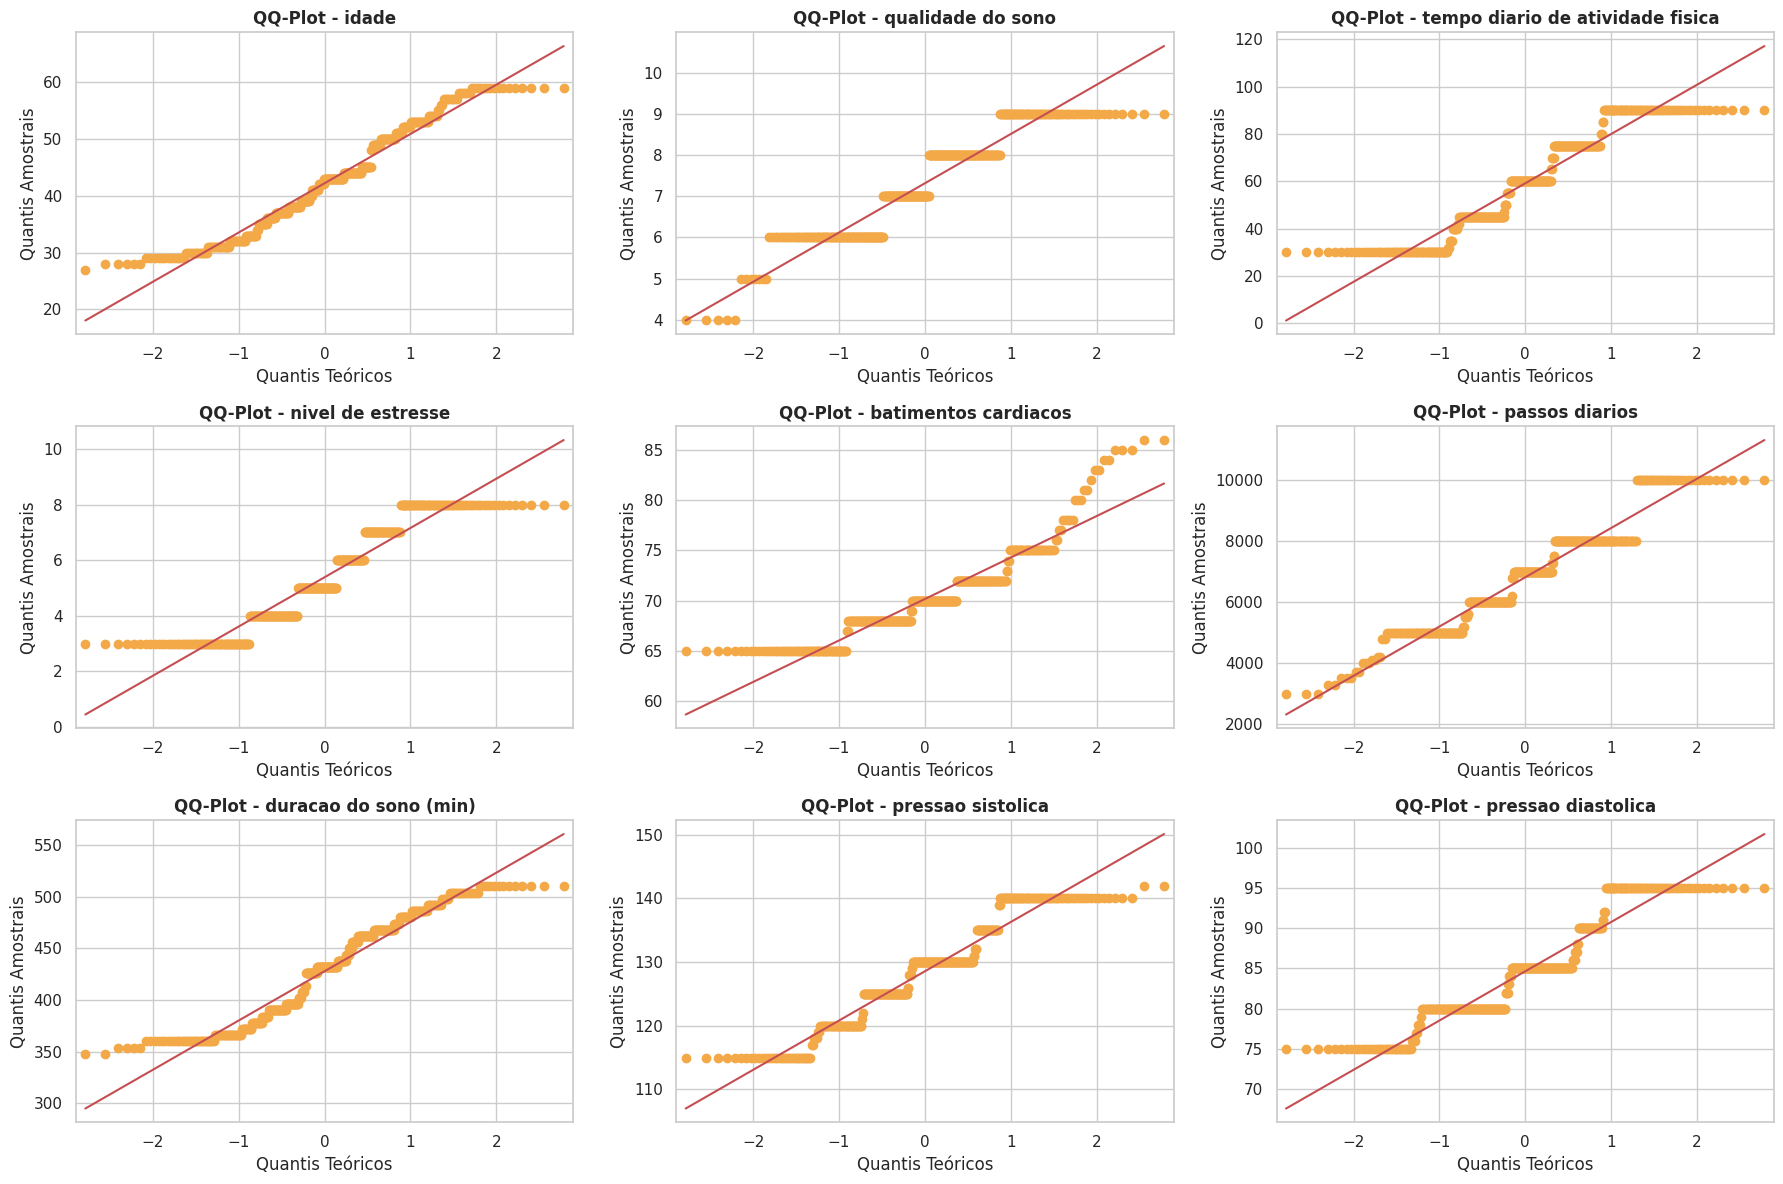

In [ ]:
# Colunas numéricas sem o ID da pessoa
colunas_numericas = df.select_dtypes(include=['int64', 'float64']).columns
if 'ID da pessoa' in colunas_numericas:
    colunas_numericas = colunas_numericas.drop('ID da pessoa')

# Configurando a grade de subplots
num_cols = len(colunas_numericas)
fig, axes = plt.subplots(nrows=(num_cols + 2) // 3, ncols=3, figsize=(18, 4 * ((num_cols + 2) // 3)))
axes = axes.flatten()

for i, col in enumerate(colunas_numericas):
    # Gerando o QQ-Plot para cada variável numérica comparando com a normal
    sm.qqplot(df[col], line='s', ax=axes[i])
    axes[i].set_title(f'QQ-Plot - {col}', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Quantis Teóricos')
    axes[i].set_ylabel('Quantis Amostrais')


plt.tight_layout()
plt.show()

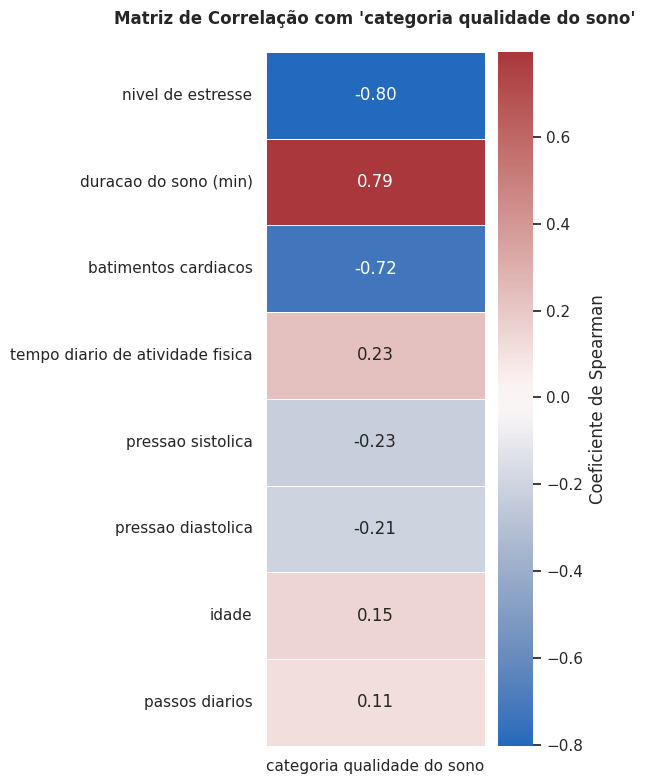

In [ ]:
# As categorias 'ruim', 'moderada' e 'boa' são mapeadas temporariamente para uma escala numérica (0, 1, 2)
df_temp = df.copy()
mapeamento_qualidade = {'ruim': 0, 'moderada': 1, 'boa': 2}
df_temp['categoria qualidade do sono_num'] = df_temp['categoria qualidade do sono'].map(mapeamento_qualidade)

# Incluindo a nova coluna numérica mapeada na lista de colunas para calcular a correlação
colunas_para_correlacao = list(colunas_numericas) + ['categoria qualidade do sono_num']

# Correlação de Spearman
matriz_correlacao = df_temp[colunas_para_correlacao].corr('spearman')

# Isolando a correlação com a target, descartando a própria variável, o ID e a qualidade subjetiva
correlacao = matriz_correlacao[['categoria qualidade do sono_num']].drop(
    ['categoria qualidade do sono_num', 'qualidade do sono', 'ID da pessoa'],
    errors='ignore'
).sort_values(by='categoria qualidade do sono_num', ascending=False, key=abs)

# Renomeando a coluna
correlacao.columns = ['categoria qualidade do sono']

# Criando o gráfico de calor (Heatmap)
plt.figure(figsize=(6, 8))
sns.heatmap(correlacao, annot=True, fmt=".2f", cmap="vlag", square=False, linewidths=0.5, cbar_kws={'label': 'Coeficiente de Spearman'})
plt.title("Matriz de Correlação com 'categoria qualidade do sono'", fontsize=12, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

#### Análises de correlação variáveis numéricas

A análise de correlação de Spearman revela a intensidade e a direção da relação entre as variáveis numéricas e a classificação da qualidade do sono (mapeada de 0 a 2):

* **`Nível de Estresse` (-0.80):** Apresenta a **correlação negativa mais forte** do conjunto de dados. Isso indica que quanto maior o nível de estresse relatado, pior é a qualidade do sono do indivíduo.
* **`Duração do Sono` (0.79):** Mostra uma **correlação positiva extremamente forte**. Isso confirma que a quantidade de tempo dormido por dia é um dos fatores mais determinantes e benéficos para alcançar uma boa qualidade de sono.
* **`Batimentos Cardíacos` (-0.72):** Possui **correlação inversa forte**. Frequências cardíacas de repouso mais elevadas estão significativamente associadas a uma classificação inferior na qualidade do sono.
* **`Pressão Sistólica` (-0.23) e `Diastólica` (-0.21):** Possuem **associações negativas discretas e fracas**. Embora haja influência na saúde geral, a variação da pressão arterial não dita diretamente a variação de qualidade de sono de maneira acentuada neste grupo.
* **`Tempo Diário de Atividade Física` (0.23):** Apresenta **correlação positiva fraca**, sugerindo que embora o exercício físico seja saudável, o tempo bruto dedicado a ele tem um papel secundário em relação à duração do sono e controle de estresse.
* **`Idade` (0.15) e `Passos Diários` (0.11):** Mostram correlações muito próximas de zero (**irrelevantes**). Isso indica que a idade ou a contagem bruta de passos não exercem influência direta na escala linear de qualidade de sono analisada.

#### Verificando correlação entre faixas etárias e qualidade de sono

A idade isoladamente apresentou uma correlação muito fraca (0.15) com a qualidade geral do sono, porém, nos é solicitado fazer a análise utilizando diferentes faixas etárias.

In [ ]:
limites_etarios = [0, 18, 23, 28, 33, 38, 43, 48, 53, 58, float('inf')]
faixas_etarias = ['até 18 anos', 'de 19 a 23 anos', 'de 24 a 28 anos', 'de 29 a 33 anos', 'de 34 a 38 anos', 'de 39 a 43 anos', 'de 44 a 48 anos', 'de 49 a 53 anos', 'de 54 a 58 anos', 'de 59 anos em diante']

df['faixa etaria'] = pd.cut(df['idade'], bins=limites_etarios, labels=faixas_etarias)
df['faixa etaria'].value_counts().sort_index()

,count
faixa etaria,
até 18 anos,0
de 19 a 23 anos,0
de 24 a 28 anos,6
de 29 a 33 anos,74
de 34 a 38 anos,66
de 39 a 43 anos,74
de 44 a 48 anos,47
de 49 a 53 anos,65
de 54 a 58 anos,26


In [ ]:
tabela_idade = pd.crosstab(
    df['faixa etaria'],
    df['categoria qualidade do sono'],
    normalize='index'
) * 100

tabela_idade.round(2)

categoria qualidade do sono,boa,moderada,ruim
faixa etaria,,,
de 24 a 28 anos,0.00,50.00,50.00
de 29 a 33 anos,48.65,51.35,0.00
de 34 a 38 anos,92.42,4.55,3.03
de 39 a 43 anos,75.68,24.32,0.00
de 44 a 48 anos,59.57,40.43,0.00
de 49 a 53 anos,52.31,47.69,0.00
de 54 a 58 anos,100.00,0.00,0.00
de 59 anos em diante,100.00,0.00,0.00


A distribuição da qualidade do sono apresenta diferenças entre as faixas etárias. Entretanto, como algumas categorias possuem poucos indivíduos, especialmente a faixa de 24 a 28 anos, essas diferenças não devem ser interpretadas isoladamente. Para obter grupos mais representativos, será realizado um agrupamento das faixas etárias.

In [ ]:
# Agrupamento das idades em três faixas com maior número de observações
df['faixa etaria ampla'] = pd.cut(
    df['idade'],
    bins=[0, 34, 44, float('inf')],
    labels=['24 a 34 anos', '35 a 44 anos', '45 anos ou mais']
)

df['faixa etaria ampla'].value_counts().sort_index()

,count
faixa etaria ampla,
24 a 34 anos,82
35 a 44 anos,168
45 anos ou mais,124


In [ ]:
tabela_idade_ampla = pd.crosstab(
    df['faixa etaria ampla'],
    df['categoria qualidade do sono'],
    normalize='index'
) * 100

tabela_idade_ampla.round(2)

categoria qualidade do sono,boa,moderada,ruim
faixa etaria ampla,,,
24 a 34 anos,43.90,50.00,6.1
35 a 44 anos,76.79,23.21,0.0
45 anos ou mais,74.19,25.81,0.0


In [ ]:
# Utilizando cramers_v para verificar intensidade da correlação

def cramers_v(tabela):
    chi2, p, _, _ = chi2_contingency(tabela)
    n = tabela.sum().sum()
    r, k = tabela.shape
    phi2 = chi2 / n
    v = np.sqrt(phi2 / min(k - 1, r - 1))
    return v

tabela = pd.crosstab(
    df['faixa etaria ampla'],
    df['categoria qualidade do sono']
)

print(f'intensidade de correlação: {cramers_v(tabela).round(3)}')

intensidade de correlação: 0.236


#### Conclusões:

* A **faixa etária** apresentou **associação moderada** com a qualidade do sono (Cramér's V = 0,236).
* O principal contraste ocorre entre o grupo de 24 a 34 anos e os grupos a partir de 35 anos, que apresentam maior concentração de boa qualidade do sono.
* A relação não apresenta um padrão linear simples com a idade, uma vez que os grupos de 35 a 44 anos e 45 anos ou mais apresentam distribuições semelhantes.

*Obs: Para a etapa de modelagem, idade será mantida como variável numérica original. A variável faixa etaria ampla será utilizada apenas para a análise exploratória.*

## **Respondendo as perguntas do desafio:**

1. **Quais variáveis mais se correlacionam com a qualidade do sono?**
* **Variável Categórica de maior correlação/associação:**
  * **`Ocupação` (Cramér's V = 0.72):** Apresentou uma associação estatisticamente significante e extremamente forte. A profissão desempenha o papel mais decisivo no padrão qualitativo de sono do indivíduo dentro das características demográficas/profissionais.
* **Variáveis Numéricas de maior correlação:**
  * **`Nível de Estresse` (Spearman = -0.80):** É a variável com maior correlação geral (negativa/inversa).
  * **`Duração do Sono em minutos` (Spearman = 0.79):** Segunda maior correlação geral (positiva).
  * **`Batimentos Cardíacos em repouso` (Spearman = -0.72):** Terceira maior correlação geral (negativa).

---

2. **Existem diferenças de padrão entre homens e mulheres? E entre faixas etárias?**

* **Entre homens e mulheres (Diferença Sutil / Força Fraca):**
  * Sim, há diferença estatística (p-valor = 0.004), mas com força de associação baixa (Cramér's V = 0.16).
  * **Padrão:** O público feminino apresenta uma proporção maior de sono de alta qualidade (**76.8%** com sono 'boa') em comparação ao masculino (**60.8%**). Os homens concentram uma fatia visivelmente maior na categoria de sono 'moderada' (**37.6%** contra **22.2%** das mulheres).
* **Entre faixas etárias (Diferença Não-Linear / Força Moderada):**
  * Sim, há diferenças claras ao agruparmos as idades de forma representativa (Cramér's V = 0.236).
  * **Padrão:** Jovens adultos (de **24 a 34 anos**) dormem pior, registrando a menor taxa de sono 'boa' (**43.9%**) e a maior taxa de sono 'moderada' (**50.0%**) e 'ruim' (**6.1%**). A partir dos **35 anos**, há uma melhora acentuada e estabilização: tanto a faixa de 35 a 44 anos quanto a de 45 anos ou mais mantêm níveis robustos e similares de sono excelente (cerca de **76.8%** e **74.2%** de sono 'boa', respectivamente).

---

3. **Quais variáveis mais impactam positivamente e negativamente a qualidade do sono?**

* **Impacto Positivo:**
  * **Duração do Sono:** Quanto maior o tempo dormido em minutos, melhor é a classificação da qualidade do sono.
  * **Ocupações Favoráveis:** Advogados(as), engenheiros(as) e contadores(as) registraram as maiores taxas de propensão a um sono de alta qualidade (100% de sono 'boa').
  * **Ausência de Transtornos do Sono:** Não possuir diagnósticos clínicos é um forte aliado (81.7% de chance de ter sono classificado como 'boa').

* **Impacto Negativo (Fatores de Risco):**
  * **Nível de Estresse:** É o fator negativo de maior impacto individual; quanto maior o estresse reportado, menor é a qualidade do sono.
  * **Batimentos Cardíacos de Repouso:** Frequências cardíacas elevadas agem como um forte indicativo biológico de sono de menor qualidade.
  * **Ocupações de Alto Risco:** Representantes de vendas (100% de sono 'ruim'), cientistas (50% de sono 'ruim' / 50% 'moderada') e vendedores(as) (100% 'moderada') configuram os perfis ocupacionais mais críticos.
  * **Presença de Transtorno do Sono:** Ter diagnósticos como insônia ou apneia reduz drasticamente as chances de um sono saudável pela metade (apenas 50.3% conseguem ter sono 'boa') e abre portas para casos de sono clinicamente degradado ('ruim').

# **Modelagem**

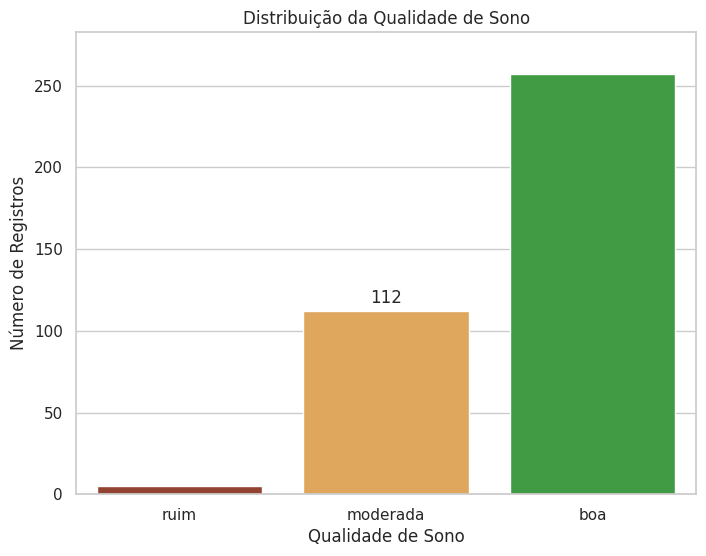

In [ ]:
# Verificando o balanceamento da variável target

plt.figure(figsize=(8, 6))
ax = sns.countplot(df,
                   x='categoria qualidade do sono',
                   order=['ruim', 'moderada', 'boa'],
                   hue='categoria qualidade do sono',
                   palette=['#F4A949', '#A23922', '#32A936'])

# Adicionando a contagem de registros sobre cada barra
ax.bar_label(ax.containers[0], padding=3)

plt.title('Distribuição da Qualidade de Sono')
plt.xlabel('Qualidade de Sono')
plt.ylabel('Número de Registros')
plt.ylim(0, df['categoria qualidade do sono'].value_counts().max() * 1.1)  # Ajuste do limite superior para acomodar os rótulos
plt.show()

In [ ]:
# Tirando colunas que podem gerar vazamento ou ruído
df_regressao = df.drop(columns=['ID da pessoa', 'qualidade do sono', 'duracao do sono (min)', 'pressao sistolica', 'pressao diastolica'])

In [ ]:
df_regressao.duplicated().sum()

np.int64(281)

**Após a remoção das colunas acima, o dataset começou a apresentar duplicatas.**  
Entendemos que isso pode ter acontecido por dois motivos:
1. Os dados foram feitos de forma sintética e repetidos para atingir uma quantidade desejada de registros;
2. Sem identificação única, alguns perfis se tornam semelhantes (dois vendedores que tenham qualidade de sono boa, por exemplo, se tornam uma duplicada).

**Para fins de aprendizado, optamos por manter o modelo final utilizando os dados duplicados.**

Como a **variável target** está **desbalanceada**, uma alternativa é usar o  parâmetro `class_weight='balanced'`.  

Em vez de tratar todas as linhas da mesma forma, o **algoritmo ajusta o "peso" da penalidade de erro durante o treinamento**. Ele calcula os pesos de forma inversamente proporcional às frequências das classes.
Na prática, isso significa que:
* A classe majoritária (com muitos exemplos) recebe um peso menor.
* A classe minoritária (com poucos exemplos) recebe un peso maior.
* O modelo passa a prestar mais atenção e a penalizar severamente os erros cometidos na classe que tem menos dados.  

In [ ]:
# Criação das variáveis
X = df_regressao.drop(columns = ['categoria qualidade do sono'])
y = df_regressao['categoria qualidade do sono']

# Divisão de dados em treino e teste
# O parâmetro stratify é importante para target desbalanceada, mantém a proporção das diferentes classes no treino e no teste

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, stratify=y, random_state=42)

print(f"Qtd treino: {X_train.shape[0]} | Qtd teste: {X_test.shape[0]}\n")
print(f'Quantidade de registros por categoria no teste:\n{y_test.value_counts()}')

Qtd treino: 299 | Qtd teste: 75

Quantidade de registros por categoria no teste:
categoria qualidade do sono
boa         52
moderada    22
ruim         1
Name: count, dtype: int64


### Regressão Logística

In [ ]:
# Identificando dinamicamente as colunas numéricas e categóricas presentes em X_train
colunas_numericas = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
colunas_categoricas = X_train.select_dtypes(include=['object', 'category']).columns.tolist()

# Preprocessador | Colunas numéricas: StandardScaler | Colunas Categóricas: OneHotEncoder
pipeline_numericas = Pipeline([
  ("padronizacao", StandardScaler())
])

pipeline_categoricas = Pipeline([
  ("codificacao", OneHotEncoder(
      handle_unknown="ignore",
      min_frequency=5,
      sparse_output=False
  ))
])

preprocessador = ColumnTransformer([
  ("numericas", pipeline_numericas, colunas_numericas),
  ("categoricas", pipeline_categoricas, colunas_categoricas)
])

# Recriando o modelo com o preprocessador atualizado
modelo = Pipeline([
  ("preprocessamento", preprocessador),
  ("classificador", LogisticRegression(
      max_iter=2000,
      class_weight="balanced",
      random_state=42
  ))
])

# Treinamento do modelo
modelo.fit(X_train, y_train)

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('numericas',
                                                  Pipeline(steps=[('padronizacao',
                                                                   StandardScaler())]),
                                                  ['idade',
                                                   'tempo diario de atividade '
                                                   'fisica',
                                                   'nivel de estresse',
                                                   'batimentos cardiacos',
                                                   'passos diarios']),
                                                 ('categoricas',
                                                  Pipeline(steps=[('codificacao',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 min_frequency=5,
                                                                                 sparse_output=False))]),
                                                  ['genero', 'ocupacao',
                                                   'classificacao do IMC',
                                                   'transtorno do sono',
                                                   'classificacao pressao',
                                                   'faixa etaria',
                                                   'faixa etaria ampla'])])),
                ('classificador',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

=== Relatório de Classificação ===
              precision    recall  f1-score   support

         boa       1.00      1.00      1.00        52
    moderada       1.00      0.95      0.98        22
        ruim       0.50      1.00      0.67         1

    accuracy                           0.99        75
   macro avg       0.83      0.98      0.88        75
weighted avg       0.99      0.99      0.99        75



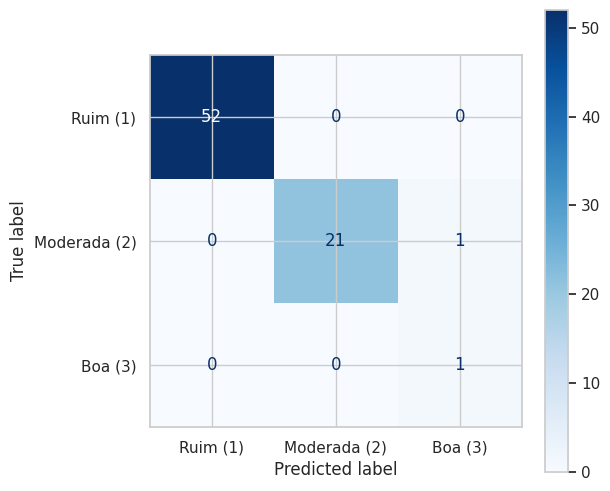

In [ ]:
# Previsão do modelo

y_pred = modelo.predict(X_test)

# Gerando o relatório de classificação (Acurácia, Precision, Recall, F1-Score)
print("=== Relatório de Classificação ===")
print(classification_report(y_test, y_pred))

# Matriz de Confusão
fig, ax = plt.subplots(figsize=(6, 6))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Ruim (1)', 'Moderada (2)', 'Boa (3)'])
disp.plot(cmap='Blues', ax=ax)
plt.show()

#### Análises

1. Desempenho Geral do Modelo:
* **Acurácia de 99%**: O modelo acertou quase a totalidade das previsões no conjunto de teste (74 de 75 amostras).

2. Análise por Classe de Qualidade de Sono
* **Classe "Boa"** (Target majoritária - 52 amostras):
    * O modelo obteve tanto **Precision** quanto **Recall** de 1.00 (100%). Isso pode indicar um **Overfitting** no modelo.  
    * **Significado prático:** Todas as 52 pessoas que realmente tinham qualidade de sono boa foram identificadas corretamente, e nenhuma pessoa de outra classe foi classificada incorretamente como "Boa".
* **Classe "Moderada"** (22 amostras):
    * **Recall** de 95%: Das 22 pessoas com qualidade de sono moderada, o modelo classificou 21 corretamente. Houve apenas 1 erro.
    * **Precision** de 1.00: Não houve falsos positivos para essa classe (ninguém de outra categoria foi rotulado erroneamente como "Moderada").
* **Classe "Ruim"** (Target altamente desbalanceada - 1 amostra):
    * **Recall** de 100%: A única amostra real de sono "Ruim" foi identificada com sucesso pelo modelo.
    * **Precision** de 50%: Houve 1 falso positivo. O modelo classificou incorretamente uma amostra da classe "Moderada" como sendo "Ruim". Por ter apenas uma amostra real no teste, a precisão matemática caiu para 50%, mas clinicamente o objetivo de detectar o caso crítico ("Ruim") foi alcançado.

3. Eficácia do Ajuste de Pesos (class_weight='balanced')
O uso de pesos balanceados funcionou perfeitamente. Em cenários sem esse ajuste, a única amostra da classe "Ruim" seria facilmente ignorada pelo algoritmo (classificada como "Boa" ou "Moderada"). Com o ajuste, o modelo conseguiu sensibilidade máxima (Recall de 1.00) para capturar o caso de risco.

4. Conclusão:  
As **duplicatas afetam o resultado do modelo** e, provavelmente por isso, ele está apresentando **Overfitting**. O modelo está “decorando” e não generalizando por conta delas e, futuramente, pode ser interessante remodelá-lo utilizando somente registros únicos.

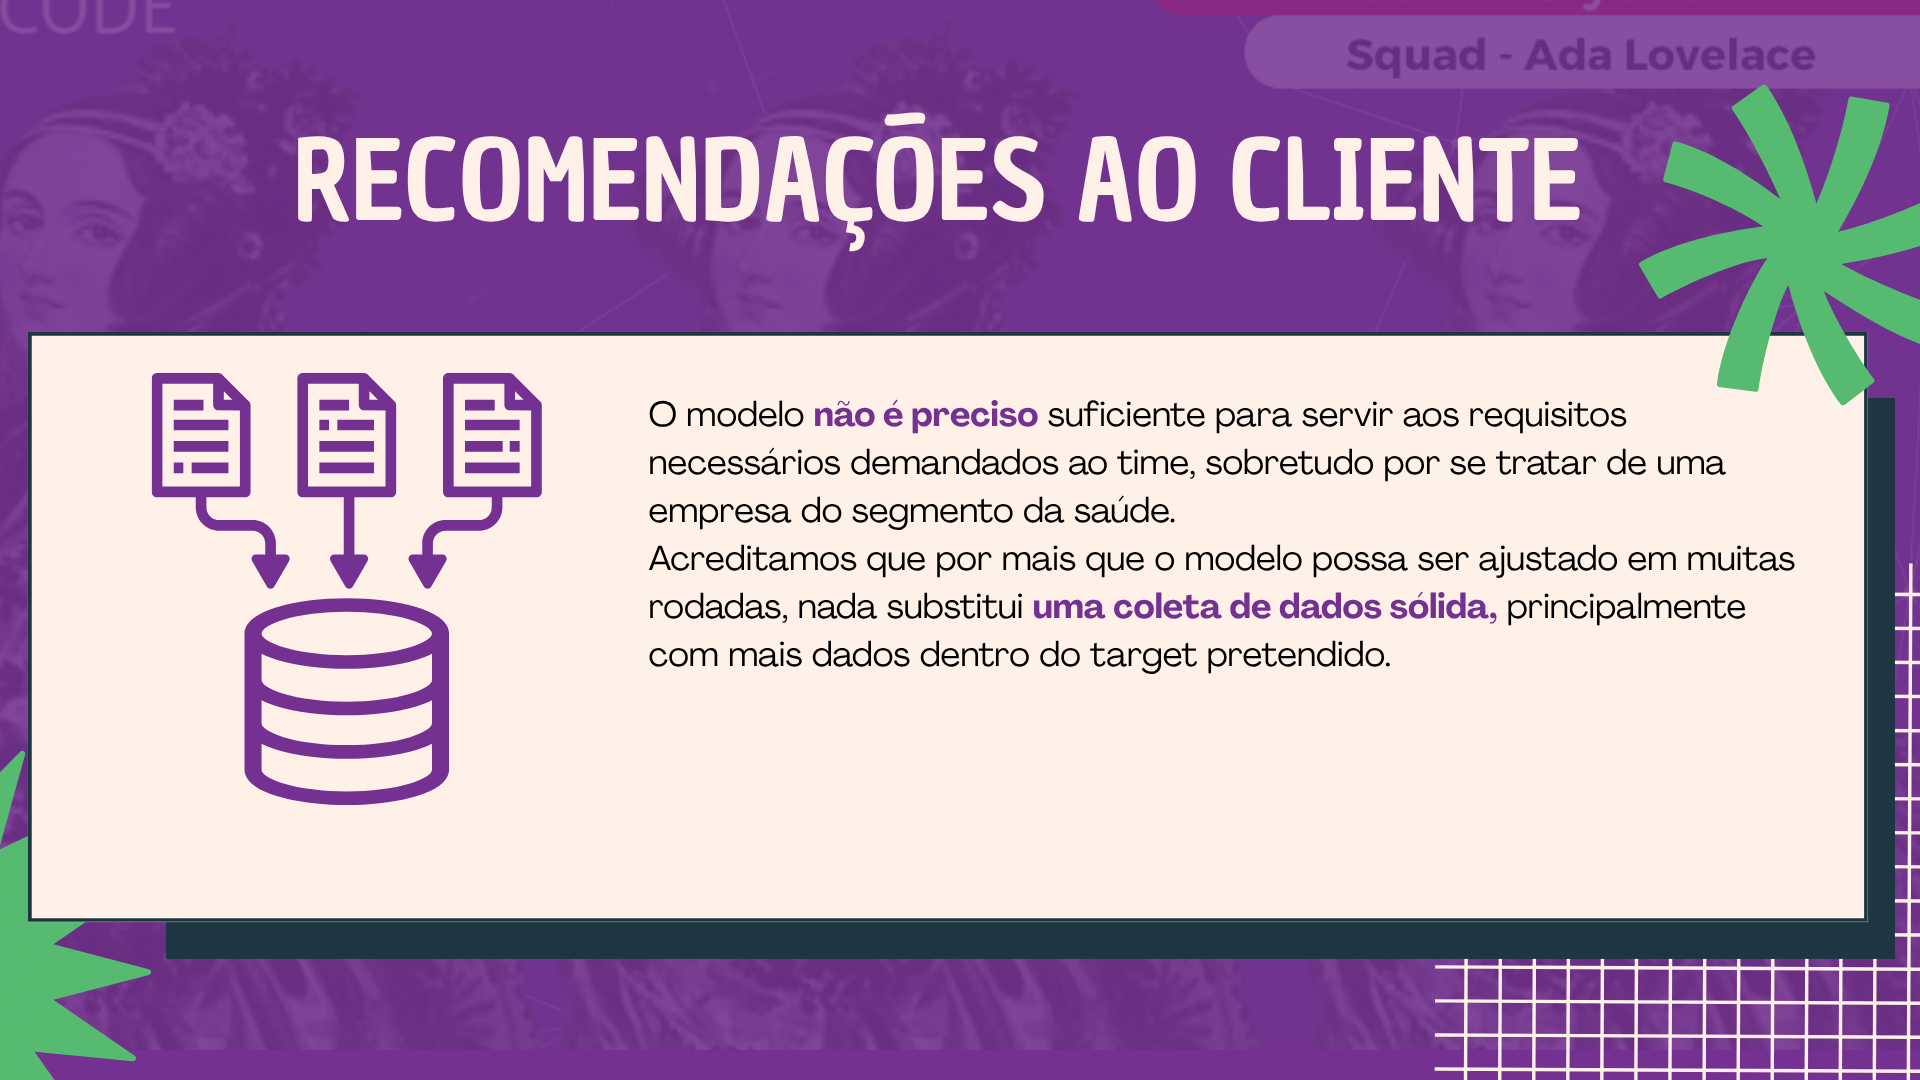

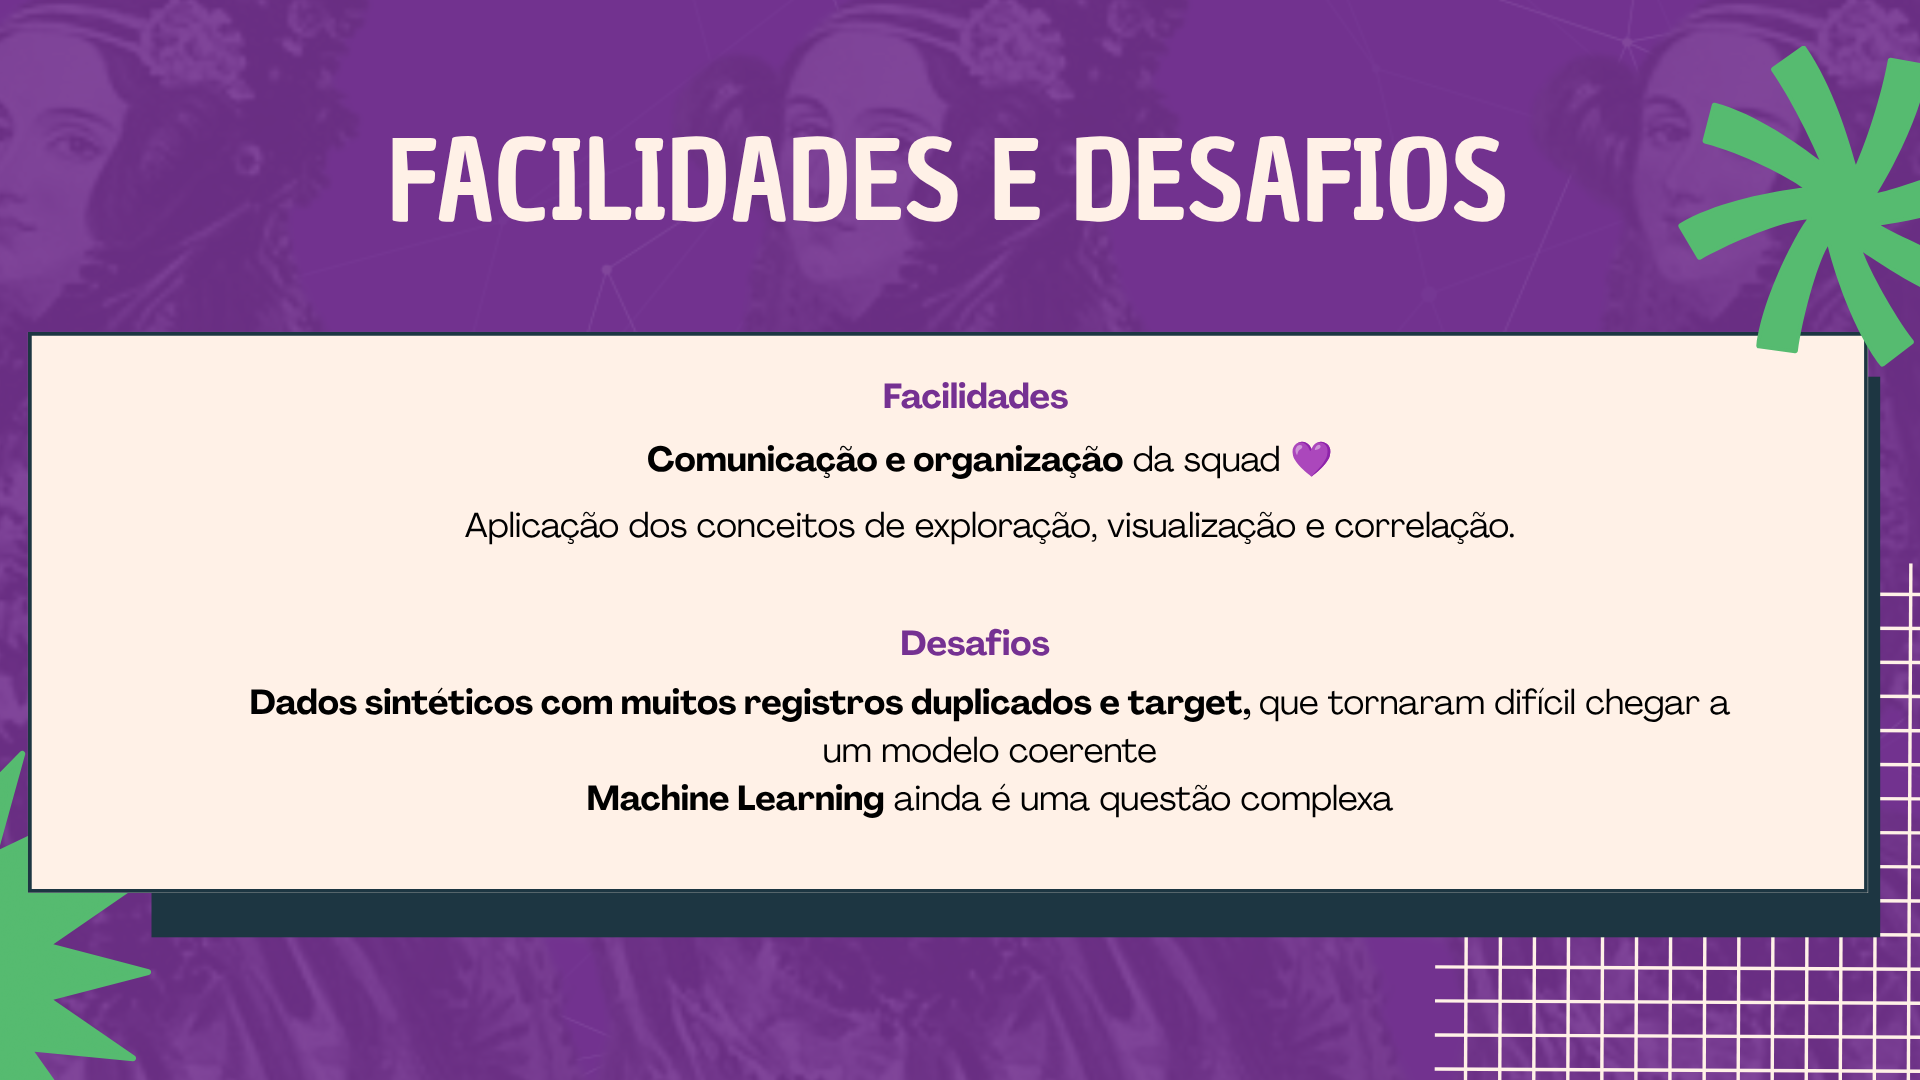